# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [21]:
ROLL_NO = 1024170333
NAME = "Sahil Sharma"

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [22]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [23]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [24]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170333   Name: Sahil Sharma   Fingerprint: 8D00EDB8   Tickets: 15

Ticket_ID                                                                             Ticket_Text
      T01                                                           The LMS says 'Not Submitted'.
      T02     Python keeps disconnecting when I use mobile hotspot. It works on another computer.
      T03                                       The server stopped responding. Please resolve it.
      T04                               The laptop is not working. The same problem occurs again.
      T05   Printer crashes while opening after restarting the system. Is there another solution?
      T06                                 The password failed to open. I don't know what changed.
      T07                     I reinstalled the WiFi after the latest update. Can you check this?
      T08                                                   Nothing works and nobody has replied.
      T09                         

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [25]:

all_results = []
rows = []

for _, ticket_row in df.iterrows():
    result = process_ticket(ticket_row["Ticket_Text"])
    all_results.append(result)
    rows.append({
        "Ticket_ID": ticket_row["Ticket_ID"],
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique tokens": len(set(result["tokens"])),
        "Final tokens": len(result["final"]),
    })

q1_df = pd.DataFrame(rows)
count_cols = ["Sentences", "Tokens", "Punctuation tokens", "Stopwords", "Unique tokens", "Final tokens"]
total_row = {"Ticket_ID": "TOTAL"}
for col in count_cols:
    total_row[col] = int(q1_df[col].sum())
total_row["Unique tokens"] = len(set(token for result in all_results for token in result["tokens"]))
q1_df = pd.concat([q1_df, pd.DataFrame([total_row])], ignore_index=True)
display(q1_df)

focus_id = FOCUS[0] if FOCUS and FOCUS[0] in set(df["Ticket_ID"]) else df.iloc[0]["Ticket_ID"]
focus_index = df.index[df["Ticket_ID"] == focus_id][0]
focus_result = all_results[focus_index]
print(f"\nDetailed preprocessing for {focus_id}: {df.loc[focus_index, 'Ticket_Text']}")
print("Tokens:", focus_result["tokens"])
print("Punctuation tokens:", focus_result["punct"])
print("Stopwords:", focus_result["stops"])
print("Final tokens:", focus_result["final"])

,Ticket_ID,Sentences,Tokens,Punctuation tokens,Stopwords,Unique tokens,Final tokens
0,T01,1,7,2,1,7,4
1,T02,2,15,2,4,14,9
2,T03,2,9,2,2,8,5
3,T04,2,12,2,6,10,4
4,T05,2,14,2,5,14,7
5,T06,2,13,2,5,12,6
6,T07,2,14,2,7,13,5
7,T08,1,7,1,2,7,4
8,T09,1,7,2,2,7,3
9,T10,2,18,2,9,15,7



Detailed preprocessing for T08: Nothing works and nobody has replied.
Tokens: ['nothing', 'works', 'and', 'nobody', 'has', 'replied', '.']
Punctuation tokens: ['.']
Stopwords: ['and', 'has']
Final tokens: ['nothing', 'works', 'nobody', 'replied']


**Observe — answer:** Some final tokens may be fragments such as `n't`, `'s`, `ca`, or `wo`. They come from contractions that `word_tokenize()` splits into separate tokens (for example, `can't` → `ca` + `n't`, and `it's` → `it` + `'s`). The official pipeline removes stopwords and punctuation, but these fragments are not necessarily classified as stopwords or punctuation, so they can remain in the final-token list.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [26]:
import re
from collections import Counter

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]
patterns = {
    "Words > 5 letters": r"\b[A-Za-z]{6,}\b",
    "Numbers (including decimals/versions)": r"(?<![\w.])\d+(?:,\d{3})*(?:\.\d+)*(?![\w.])",
    "Capitalized words": r"\b[A-Z][a-zA-Z]*\b",
    "Words starting with a vowel": r"\b[AEIOUaeiou][a-zA-Z]*\b",
}

print("EXTRACTION FROM RAW TICKETS")
for label, pattern in patterns.items():
    print(f"\n--- {label} ---")
    for _, ticket_row in df.iterrows():
        print(f"{ticket_row['Ticket_ID']}: {re.findall(pattern, ticket_row['Ticket_Text'])}")

email_pattern = r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"
url_pattern = r"https?://[^\s<>]+|www\.[^\s<>]+"
phone_pattern = r"(?<!\w)(?:\+\d{1,3}[- ]?)?(?:\d{5}[- ]\d{5}|\d{4}[- ]\d{3}[- ]\d{4}|\d{3}[- ]\d{3}[- ]\d{4})(?!\w)"

def replace_patterns(text):
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text

print("\nREPLACEMENT TESTS ON TEST_LINES")
for line in TEST_LINES:
    print(replace_patterns(line))
print("\nREPLACEMENT ON RAW TICKETS")
for _, ticket_row in df.iterrows():
    print(f"{ticket_row['Ticket_ID']}: {replace_patterns(ticket_row['Ticket_Text'])}")

# Estimate capitalized words occurring at sentence starts, then report the observed count.
capitalized = []
sentence_initial_capitalized = []
for text in df["Ticket_Text"]:
    capitalized.extend(re.findall(patterns["Capitalized words"], text))
    for sentence in re.split(r"(?<=[.!?])\s+", text):
        match = re.match(r"\s*([A-Z][a-zA-Z]*)\b", sentence)
        if match:
            sentence_initial_capitalized.append(match.group(1))
# A practical heuristic: count sentence-initial capitalized occurrences whose lowercase form also
# appears elsewhere in lowercase, suggesting capitalization may be due to sentence position.
lowercase_noninitial_words = set()
for text in df["Ticket_Text"]:
    for sentence in re.split(r"(?<=[.!?])\s+", text):
        first = re.match(r"\s*[A-Z][a-zA-Z]*\b", sentence)
        remainder = sentence[first.end():] if first else sentence
        lowercase_noninitial_words.update(re.findall(r"\b[a-z]+\b", remainder))
likely_sentence_capitalization = [word for word in sentence_initial_capitalized if word.lower() in lowercase_noninitial_words]
print(f"\nCapitalized-word matches: {len(capitalized)}")
print(f"Sentence-initial capitalized occurrences: {len(sentence_initial_capitalized)}")
print(f"Likely capitalized only because of sentence position (heuristic): {len(likely_sentence_capitalization)}")
print("Likely examples:", likely_sentence_capitalization[:15])

EXTRACTION FROM RAW TICKETS

--- Words > 5 letters ---
T01: ['Submitted']
T02: ['Python', 'disconnecting', 'mobile', 'hotspot', 'another', 'computer']
T03: ['server', 'stopped', 'responding', 'Please', 'resolve']
T04: ['laptop', 'working', 'problem', 'occurs']
T05: ['Printer', 'crashes', 'opening', 'restarting', 'system', 'another', 'solution']
T06: ['password', 'failed', 'changed']
T07: ['reinstalled', 'latest', 'update']
T08: ['Nothing', 'nobody', 'replied']
T09: ['helpdesk', 'university']
T10: ['cannot', 'access', 'mobile', 'hotspot', 'problem', 'occurs']
T11: ['working', 'worked', 'yesterday']
T12: ['student', 'portal', 'restarting', 'system', 'changed']
T13: ['failed']
T14: ['uploaded']
T15: ['resetting', 'password', 'several']

--- Numbers (including decimals/versions) ---
T01: []
T02: []
T03: []
T04: []
T05: []
T06: []
T07: []
T08: []
T09: []
T10: []
T11: []
T12: []
T13: []
T14: ['95.5']
T15: []

--- Capitalized words ---
T01: ['The', 'LMS', 'Not', 'Submitted']
T02: ['Python', '

**Observe — answer:** The Q2 cell prints a dataset-specific estimate and examples. It counts sentence-initial capitalized words whose lowercase form also occurs elsewhere in lowercase, which is a practical heuristic for capitalization caused by sentence position. The estimate is not perfect because proper names and technical terms (e.g. `Python`, `MATLAB`, `VPN`) can also appear at the start of a sentence.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [27]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

token_pattern = (
    r"https?://[^\s<>]+|www\.[^\s<>]+|"
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|"
    r"(?<!\w)(?:\+\d{1,3}[- ]?)?(?:\d{5}[- ]\d{5}|\d{4}[- ]\d{3}[- ]\d{4}|\d{3}[- ]\d{3}[- ]\d{4})(?!\w)|"
    r"\b\d+(?:,\d{3})*(?:\.\d+)+\b|"
    r"\b[A-Za-z]+(?:-[A-Za-z]+)+\b|"
    r"\b[A-Za-z]+(?:['’][A-Za-z]+)+\b|"
    r"\b[A-Za-z]+\b|"
    r"\d+(?:,\d{3})*(?:\.\d+)?|"
    r"[^\w\s]"
)
my_tokenizer = RegexpTokenizer(token_pattern)

def my_tokenize(text):
    """Tokenize while preserving URLs, emails, phone numbers, versions, decimals, hyphens and contractions."""
    return my_tokenizer.tokenize(text)

print("TEST_LINES: custom tokenizer vs NLTK word_tokenize")
for i, line in enumerate(TEST_LINES, start=1):
    print(f"\nTest line {i}: {line}")
    print("my_tokenize:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

comparison_rows = []
for _, ticket_row in df.iterrows():
    text = ticket_row["Ticket_Text"]
    custom_tokens = my_tokenize(text)
    nltk_tokens = word_tokenize(text)
    comparison_rows.append({
        "Ticket_ID": ticket_row["Ticket_ID"],
        "Custom tokens": custom_tokens,
        "word_tokenize tokens": nltk_tokens,
        "Custom count": len(custom_tokens),
        "NLTK count": len(nltk_tokens),
        "Different?": custom_tokens != nltk_tokens,
    })
q3_df = pd.DataFrame(comparison_rows)
display(q3_df)
different_ticket_count = int(q3_df["Different?"].sum())
print(f"Tickets with different token sequences: {different_ticket_count} / {len(q3_df)}")

TEST_LINES: custom tokenizer vs NLTK word_tokenize

Test line 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Test line 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Test line 3: The state-of

,Ticket_ID,Custom tokens,word_tokenize tokens,Custom count,NLTK count,Different?
0,T01,"[The, LMS, says, ', Not, Submitted, ', .]","[The, LMS, says, 'Not, Submitted, ', .]",8,7,True
1,T02,"[Python, keeps, disconnecting, when, I, use, m...","[Python, keeps, disconnecting, when, I, use, m...",15,15,False
2,T03,"[The, server, stopped, responding, ., Please, ...","[The, server, stopped, responding, ., Please, ...",9,9,False
3,T04,"[The, laptop, is, not, working, ., The, same, ...","[The, laptop, is, not, working, ., The, same, ...",12,12,False
4,T05,"[Printer, crashes, while, opening, after, rest...","[Printer, crashes, while, opening, after, rest...",14,14,False
5,T06,"[The, password, failed, to, open, ., I, don't,...","[The, password, failed, to, open, ., I, do, n'...",12,13,True
6,T07,"[I, reinstalled, the, WiFi, after, the, latest...","[I, reinstalled, the, WiFi, after, the, latest...",14,14,False
7,T08,"[Nothing, works, and, nobody, has, replied, .]","[Nothing, works, and, nobody, has, replied, .]",7,7,False
8,T09,"[Email, me, at, helpdesk@university.edu, .]","[Email, me, at, helpdesk, @, university.edu, .]",5,7,True
9,T10,"[I, cannot, access, the, VPN, when, I, use, mo...","[I, can, not, access, the, VPN, when, I, use, ...",17,18,True


Tickets with different token sequences: 6 / 15


**Observe — answer:** The exact number of tickets with different token sequences is printed by the Q3 cell. Typical differences are: (1) the custom tokenizer keeps `isn't` as one token while `word_tokenize()` splits it into `is` and `n't`; (2) it keeps `state-of-the-art` as one token while the standard tokenizer separates its hyphenated components; and (3) it can preserve `2.0.1`, an email address, URL, or phone number as one token rather than splitting it into smaller pieces.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [28]:
import nltk
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

for pkg in ["averaged_perceptron_tagger", "averaged_perceptron_tagger_eng", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

porter = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()

unique_final_tokens = list(dict.fromkeys(
    token.lower() for result in all_results for token in result["final"] if token.isalpha()
))
suffix_candidates = ["ing", "edly", "ed", "ly", "ies", "s"]
chosen_suffix = next((suffix for suffix in suffix_candidates
                      if sum(word.endswith(suffix) and len(word) > len(suffix) + 2
                             for word in unique_final_tokens) >= 2), "ing")
regex_stemmer = RegexpStemmer(chosen_suffix + r"$", min=3)
print("RegexpStemmer suffix selected:", repr(chosen_suffix))
print("Dataset words supporting this suffix:", [w for w in unique_final_tokens if w.endswith(chosen_suffix) and len(w) > len(chosen_suffix) + 2][:10])

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("N"):
        return wordnet.NOUN
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

pos_tags = nltk.pos_tag(unique_final_tokens)
rows = []
for word, tag in pos_tags:
    pos = get_wordnet_pos(tag)
    results = {
        "Porter Stem": porter.stem(word),
        "Lancaster Stem": lancaster.stem(word),
        "Regexp Stem": regex_stemmer.stem(word),
        "WordNet Lemma": lemmatizer.lemmatize(word, pos=pos),
    }
    if len(set(results.values())) > 1:
        rows.append({"Word": word, "POS Tag": tag, **results})
q4_df = pd.DataFrame(rows, columns=["Word", "POS Tag", "Porter Stem", "Lancaster Stem", "Regexp Stem", "WordNet Lemma"])
display(q4_df)
print("Unique alphabetic final tokens:", len(unique_final_tokens))
print("Words with differing outputs:", len(q4_df))


if not q4_df.empty:
    print("Examples from the differing-output table:")
    display(q4_df.head(10))

RegexpStemmer suffix selected: 'ing'
Dataset words supporting this suffix: ['disconnecting', 'responding', 'working', 'opening', 'restarting', 'nothing', 'resetting']


,Word,POS Tag,Porter Stem,Lancaster Stem,Regexp Stem,WordNet Lemma
0,lms,NNS,lm,lms,lms,lm
1,says,VBZ,say,say,says,say
2,submitted,VBN,submit,submit,submitted,submit
3,keeps,NNS,keep,keep,keeps,keep
4,use,NN,use,us,use,use
5,mobile,JJ,mobil,mobl,mobile,mobile
6,works,VBZ,work,work,works,work
7,another,DT,anoth,anoth,another,another
8,computer,NN,comput,comput,computer,computer
9,server,NN,server,serv,server,server


Unique alphabetic final tokens: 55
Words with differing outputs: 37
Examples from the differing-output table:


,Word,POS Tag,Porter Stem,Lancaster Stem,Regexp Stem,WordNet Lemma
0,lms,NNS,lm,lms,lms,lm
1,says,VBZ,say,say,says,say
2,submitted,VBN,submit,submit,submitted,submit
3,keeps,NNS,keep,keep,keeps,keep
4,use,NN,use,us,use,use
5,mobile,JJ,mobil,mobl,mobile,mobile
6,works,VBZ,work,work,works,work
7,another,DT,anoth,anoth,another,another
8,computer,NN,comput,comput,computer,computer
9,server,NN,server,serv,server,server


**Observe — answer:** Use the displayed Q4 table to select examples from this generated dataset. **Over-stemming** occurs when a stemmer removes too much and produces an unrelated or overly short form; Lancaster is often more aggressive than Porter. **Under-stemming** occurs when related forms remain different because a suffix rule does not cover them. The table lets you cite the exact token and outputs rather than relying on a generic example.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total tokens,Unique tokens,TTR
0,S1 (All tokens),180,89,0.4944
1,S2 (No punctuation),151,83,0.5497
2,S3 (Final tokens),84,59,0.7024
3,S4 (S3 after Porter stemming),84,56,0.6667



Top 10 words in S1:


,Word,Frequency
0,.,22
1,the,16
2,i,9
3,is,4
4,after,4
5,open,4
6,n't,4
7,lms,3
8,it,3
9,not,3


Top 10 words in S3:


,Word,Frequency
0,open,4
1,n't,4
2,lms,3
3,use,2
4,mobile,2
5,hotspot,2
6,works,2
7,another,2
8,working,2
9,problem,2


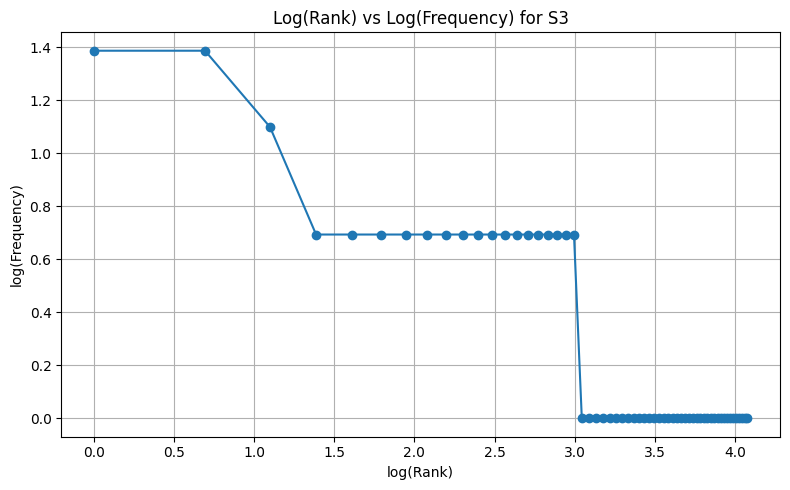

Top 5 bigrams in S1:


,Bigram,Frequency
0,"(., i)",7
1,"(., the)",6
2,"(the, lms)",3
3,"(when, i)",2
4,"(i, use)",2


Top 5 bigrams in S3:


,Bigram,Frequency
0,"(use, mobile)",2
1,"(mobile, hotspot)",2
2,"(problem, occurs)",2
3,"(restarting, system)",2
4,"(failed, open)",2


In [29]:
import matplotlib.pyplot as plt
from collections import Counter
from nltk.util import bigrams
from math import log

S1 = [token.lower() for result in all_results for token in result["tokens"]]
S2 = [token.lower() for result in all_results for token in result["tokens"] if not is_punct(token)]
S3 = [token.lower() for result in all_results for token in result["final"]]
S4 = [porter.stem(token) for token in S3]

corpora = {"S1 (All tokens)": S1, "S2 (No punctuation)": S2,
           "S3 (Final tokens)": S3, "S4 (S3 after Porter stemming)": S4}
stats_rows = []
for corpus_name, tokens in corpora.items():
    stats_rows.append({"Corpus": corpus_name, "Total tokens": len(tokens),
                       "Unique tokens": len(set(tokens)),
                       "TTR": round(len(set(tokens)) / len(tokens), 4) if tokens else 0})
stats_df = pd.DataFrame(stats_rows)
display(stats_df)

print("\nTop 10 words in S1:")
display(pd.DataFrame(Counter(S1).most_common(10), columns=["Word", "Frequency"]))
print("Top 10 words in S3:")
display(pd.DataFrame(Counter(S3).most_common(10), columns=["Word", "Frequency"]))

freq_s3 = Counter(S3).most_common()
ranks = list(range(1, len(freq_s3) + 1))
frequencies = [frequency for _, frequency in freq_s3]
plt.figure(figsize=(8, 5))
plt.plot([log(rank) for rank in ranks], [log(freq) for freq in frequencies], marker="o", linestyle="-")
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.tight_layout()
plt.show()

print("Top 5 bigrams in S1:")
display(pd.DataFrame(Counter(bigrams(S1)).most_common(5), columns=["Bigram", "Frequency"]))
print("Top 5 bigrams in S3:")
display(pd.DataFrame(Counter(bigrams(S3)).most_common(5), columns=["Bigram", "Frequency"]))

**Observe — answer:** TTR is the number of unique token types divided by the total number of tokens. From S1 to S4, punctuation and stopwords are excluded before S3 is formed, and Porter stemming then maps inflected or related forms to shared stems in S4. Removing tokens can raise TTR if many repeated tokens are removed, while merging word forms can lower the number of unique types; the direction and size of the change therefore depend on this generated ticket dataset. Refer to the Q5 table for the actual values.

---
## Q6. Interpretation (required by the assignment PDF)
Answer the four questions using examples from the output generated above.

In [30]:

print("(a) TTR change from S1 to S4:")
display(stats_df)
row_s1 = stats_df.loc[stats_df["Corpus"] == "S1 (All tokens)"].iloc[0]
row_s4 = stats_df.loc[stats_df["Corpus"] == "S4 (S3 after Porter stemming)"].iloc[0]
print(f"In this dataset, TTR changes from {row_s1['TTR']} (S1) to {row_s4['TTR']} (S4). S1 includes punctuation and stopwords; S4 contains the final tokens after Porter stemming. Stemming merges some word forms, reducing vocabulary size relative to token count.")

print("\n(b) Example where tokenizers differ:")
example_line = next((line for line in TEST_LINES if my_tokenize(line) != word_tokenize(line)), TEST_LINES[0])
print("Text:", example_line)
print("my_tokenize:", my_tokenize(example_line))
print("word_tokenize:", word_tokenize(example_line))
print("Explanation: the custom regex keeps selected forms such as contractions, hyphenated words, versions, URLs, emails and phone numbers intact, while word_tokenize may split them.")

print("\n(c) Candidate over-stemming example from this dataset:")
over_candidates = q4_df[(q4_df["Lancaster Stem"] != q4_df["Word"]) &
                         (q4_df["Lancaster Stem"].str.len() <= q4_df["Word"].str.len() - 3)] if not q4_df.empty else q4_df
if not over_candidates.empty:
    candidate = over_candidates.iloc[0]
    print(f"Word: {candidate['Word']!r}; Lancaster output: {candidate['Lancaster Stem']!r}; Porter output: {candidate['Porter Stem']!r}; WordNet lemma: {candidate['WordNet Lemma']!r}")
    print("Use this as an over-stemming example only if the reduced form visibly loses useful meaning; briefly explain the loss.")
else:
    print("No clear over-stemming candidate was found automatically. Inspect the displayed Q4 table and choose an output that removes too much meaning.")

print("\n(d) Candidate where POS-aware lemmatization is more interpretable:")
lemma_candidates = q4_df[(q4_df["WordNet Lemma"] != q4_df["Word"]) &
                         (q4_df["WordNet Lemma"] != q4_df["Porter Stem"])] if not q4_df.empty else q4_df
if not lemma_candidates.empty:
    candidate = lemma_candidates.iloc[0]
    print(f"Word: {candidate['Word']!r}; POS: {candidate['POS Tag']}; Porter: {candidate['Porter Stem']!r}; WordNet lemma: {candidate['WordNet Lemma']!r}")
    print("Explain that WordNet uses the POS tag to return a dictionary form, whereas a stemmer mechanically strips or transforms suffixes.")
else:
    print("No clear example found automatically; inspect Q4 for a word whose POS-aware lemma is a meaningful dictionary form unlike its stem.")

(a) TTR change from S1 to S4:


,Corpus,Total tokens,Unique tokens,TTR
0,S1 (All tokens),180,89,0.4944
1,S2 (No punctuation),151,83,0.5497
2,S3 (Final tokens),84,59,0.7024
3,S4 (S3 after Porter stemming),84,56,0.6667


In this dataset, TTR changes from 0.4944 (S1) to 0.6667 (S4). S1 includes punctuation and stopwords; S4 contains the final tokens after Porter stemming. Stemming merges some word forms, reducing vocabulary size relative to token count.

(b) Example where tokenizers differ:
Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
Explanation: the custom regex keeps selected forms such as contractions, hyphenated words, versions, URLs, emails and phone numbers intact, while word_tokenize may split them.

(c) Candidate over-stemming example from this dataset:
Word: 'submitted'; Lancaster output: 'submit